Question 3
Worked Numerical Solution

**Student ID:** 23K-0073
**Course:** Agentic AI (AI4015) · Fall 2026

**Prompt:** “The patient was admitted to the ___”  
**Target token:** **hospital**



| Index | Candidate word | Teacher logit | Student logit | One-hot label |
|:--:|---|---:|---:|---:|
| 1 | hospital | 5.0 | 3.0 | 1 |
| 2 | clinic | 3.0 | 2.5 | 0 |
| 3 | ward | 2.0 | 1.0 | 0 |
| 4 | school | 0.0 | 0.5 | 0 |

Given: **temperature** T=2, **mixing weight** $\alpha=0.5$, **learning rate** $\eta=0.5$.

$$\mathcal L=\alpha\tau^2D_{KL}(p_\tau\parallel q_\tau)+(1-\alpha)H(y,q_1)$$

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda value: f"{value:.6f}")

vocab = ["hospital", "clinic", "ward", "school"]
teacher = np.array([5.0, 3.0, 2.0, 0.0], dtype=float)
student = np.array([3.0, 2.5, 1.0, 0.5], dtype=float)
target = np.array([1.0, 0.0, 0.0, 0.0], dtype=float)
tau, alpha, learning_rate = 2.0, 0.5, 0.5

def probabilities(logits, temperature=1.0):
    """Softmax with max subtraction for numerical stability."""
    scaled = logits / temperature
    stable = scaled - scaled.max()
    numerator = np.exp(stable)
    return numerator / numerator.sum()

def softmax_work(logits, temperature):
    scaled = logits / temperature
    shifted = scaled - scaled.max()
    terms = np.exp(shifted)
    result = probabilities(logits, temperature)
    return pd.DataFrame({
        "word": vocab,
        "logit": logits,
        "logit / T": scaled,
        "exp(shifted logit)": terms,
        "probability": result,
    }), terms.sum()

print("Inputs loaded. Logit order:", ", ".join(vocab))

Inputs loaded. Logit order: hospital, clinic, ward, school


## (a) Teacher and student probabilities at $T=1$

For a logit vector $z$, softmax is:

$$P_i=\frac{e^{z_i}}{\sum_j e^{z_j}}$$

To avoid working with very large exponentials, we can subtract the **largest logit** from every entry first; softmax does not change.

For the **teacher**, subtract $5$:

$$[5,3,2,0]-5=[0,-2,-3,-5]$$
$$Z_t=e^0+e^{-2}+e^{-3}+e^{-5}=1.191860$$

For the **student**, subtract $3$:

$$[3,2.5,1,0.5]-3=[0,-0.5,-2,-2.5]$$
$$Z_s=e^0+e^{-0.5}+e^{-2}+e^{-2.5}=1.823951$$

The tables show the terms used in each denominator and the resulting probabilities.

In [ ]:
pt_1 = probabilities(teacher, 1)
ps_1 = probabilities(student, 1)
for name, vector in [("TEACHER", teacher), ("STUDENT", student)]:
    table, denominator = softmax_work(vector, 1)
    print(f"\n{name} (T=1)  denominator = {denominator:.6f}")
    print(table.to_string(index=False))

assert np.isclose(pt_1.sum(), 1.0) and np.isclose(ps_1.sum(), 1.0)


TEACHER (T=1)  denominator = 1.191860
    word    logit  logit / T  exp(shifted logit)  probability
hospital 5.000000   5.000000            1.000000     0.839025
  clinic 3.000000   3.000000            0.135335     0.113550
    ward 2.000000   2.000000            0.049787     0.041773
  school 0.000000   0.000000            0.006738     0.005653

STUDENT (T=1)  denominator = 1.823951
    word    logit  logit / T  exp(shifted logit)  probability
hospital 3.000000   3.000000            1.000000     0.548260
  clinic 2.500000   2.500000            0.606531     0.332537
    ward 1.000000   1.000000            0.135335     0.074199
  school 0.500000   0.500000            0.082085     0.045004


**Answer (a)** (in the word order used above):

$$\boxed{p_1=[0.839025,\ 0.113550,\ 0.041773,\ 0.005653]}$$
$$\boxed{q_1=[0.548260,\ 0.332537,\ 0.074199,\ 0.045004]}$$

The teacher assigns a noticeably higher probability to **hospital** than the student does.

## (b) Softened probabilities at $T=2$

Temperature scales each logit before exponentiation:

$$P_{\tau,i}=\frac{e^{z_i/\tau}}{\sum_j e^{z_j/\tau}},\qquad \tau=2$$

Teacher logits after scaling: $[2.5,1.5,1,0]$.  
Student logits after scaling: $[1.5,1.25,0.5,0.25]$.

The shifted exponentials and normalization factors are recomputed below.

In [ ]:
pt_2 = probabilities(teacher, tau)
ps_2 = probabilities(student, tau)
for name, vector in [("TEACHER", teacher), ("STUDENT", student)]:
    table, denominator = softmax_work(vector, tau)
    print(f"\n{name} (T=2)  denominator = {denominator:.6f}")
    print(table.to_string(index=False))


TEACHER (T=2)  denominator = 1.673095
    word    logit  logit / T  exp(shifted logit)  probability
hospital 5.000000   2.500000            1.000000     0.597695
  clinic 3.000000   1.500000            0.367879     0.219880
    ward 2.000000   1.000000            0.223130     0.133364
  school 0.000000   0.000000            0.082085     0.049062

STUDENT (T=2)  denominator = 2.433185
    word    logit  logit / T  exp(shifted logit)  probability
hospital 3.000000   1.500000            1.000000     0.410984
  clinic 2.500000   1.250000            0.778801     0.320075
    ward 1.000000   0.500000            0.367879     0.151193
  school 0.500000   0.250000            0.286505     0.117749


**Answer (b):**

$$\boxed{p_2=[0.597695,\ 0.219880,\ 0.133364,\ 0.049062]}$$
$$\boxed{q_2=[0.410984,\ 0.320075,\ 0.151193,\ 0.117749]}$$

Raising the temperature from 1 to 2 makes the distributions less peaked.

## (c) KL divergence of the softened probabilities

The teacher's softened probabilities are the reference distribution:

$$D_{KL}(p_2\parallel q_2)=\sum_{i=1}^4p_{2,i}\ln\left(\frac{p_{2,i}}{q_{2,i}}\right)$$

We evaluate **all four terms** and then add them. Individual terms can be negative; the complete KL divergence is nonnegative.

In [ ]:
log_ratio = np.log(pt_2 / ps_2)
kl_terms = pt_2 * log_ratio
kl_value = kl_terms.sum()

kl_detail = pd.DataFrame({
    "word": vocab,
    "teacher p2": pt_2,
    "student q2": ps_2,
    "ln(p2/q2)": log_ratio,
    "p2 × ln(p2/q2)": kl_terms,
})
print(kl_detail.to_string(index=False))
print(f"\nKL = {' + '.join(f'({x:+.6f})' for x in kl_terms)}")
print(f"KL = {kl_value:.9f}")

    word  teacher p2  student q2  ln(p2/q2)  p2 × ln(p2/q2)
hospital    0.597695    0.410984   0.374526        0.223852
  clinic    0.219880    0.320075  -0.375474       -0.082559
    ward    0.133364    0.151193  -0.125474       -0.016734
  school    0.049062    0.117749  -0.875474       -0.042952

KL = (+0.223852) + (-0.082559) + (-0.016734) + (-0.042952)
KL = 0.081607314


Using the term values:

$$KL\approx0.223852-0.082559-0.016734-0.042952$$

$$\boxed{D_{KL}(p_2\parallel q_2)=0.081607}$$

## (d) Cross-entropy with the hard label

The gold label is $y=[1,0,0,0]$. Cross-entropy is:

$$H(y,q_1)=-\sum_i y_i\ln q_{1,i}$$

Because only the first entry of $y$ is 1, every other term disappears:

$$H(y,q_1)=-\ln P_{\mathrm{student}}(\mathrm{hospital}\mid T=1)$$

In [ ]:
ce_value = -np.dot(target, np.log(ps_1))
print(f"CE = -ln({ps_1[0]:.9f})")
print(f"CE = {ce_value:.9f}")

CE = -ln(0.548260360)
CE = 0.601004995


$$\boxed{H(y,q_1)=0.601005}$$

## (e) Combine the two terms into the distillation loss

Substituting $\tau=2$ and $\alpha=0.5$:

$$\begin{aligned}
\mathcal L&=0.5(2)^2(0.081607)+0.5(0.601005)\\
&=2(0.081607)+0.5(0.601005)
\end{aligned}$$

The code keeps full precision during multiplication and only rounds for display.

In [ ]:
soft_component = alpha * tau**2 * kl_value
hard_component = (1 - alpha) * ce_value
loss_before = soft_component + hard_component

print(f"Soft-target contribution = {alpha:.1f} × {tau:.0f}² × {kl_value:.9f} = {soft_component:.9f}")
print(f"Hard-label contribution  = {1-alpha:.1f} × {ce_value:.9f} = {hard_component:.9f}")
print(f"Initial total loss       = {soft_component:.9f} + {hard_component:.9f} = {loss_before:.9f}")

Soft-target contribution = 0.5 × 2² × 0.081607314 = 0.163214628
Hard-label contribution  = 0.5 × 0.601004995 = 0.300502498
Initial total loss       = 0.163214628 + 0.300502498 = 0.463717126


$$\boxed{\mathcal L_{\mathrm{initial}}=0.463717}$$

## (f) Gradient with respect to the student logits

We differentiate the two parts separately.

For the hard-label term:

$$\frac{\partial H(y,q_1)}{\partial z_s}=q_1-y$$

For the softened KL term, the softmax is evaluated at $z_s/\tau$:

$$\frac{\partial D_{KL}(p_2\parallel q_2)}{\partial z_s}=\frac{q_2-p_2}{\tau}$$

Apply the weights from the original loss:

$$\begin{aligned}
\nabla_{z_s}\mathcal L
&=\alpha\tau^2\left(\frac{q_2-p_2}{\tau}\right)+(1-\alpha)(q_1-y)\\
&=\alpha\tau(q_2-p_2)+(1-\alpha)(q_1-y)
\end{aligned}$$

With $\alpha=0.5$ and $\tau=2$:

$$\boxed{\nabla_{z_s}\mathcal L=(q_2-p_2)+0.5(q_1-y)}$$

We calculate each of the four logit gradients below.

In [ ]:
from_soft_targets = alpha * tau * (ps_2 - pt_2)
from_label = (1 - alpha) * (ps_1 - target)
gradients = from_soft_targets + from_label

grad_table = pd.DataFrame({
    "word": vocab,
    "soft gradient": from_soft_targets,
    "label gradient": from_label,
    "total gradient": gradients,
})
print(grad_table.to_string(index=False))
print("\nGradient:", np.array2string(gradients, precision=9))
print("Sum of components =", f"{gradients.sum():.12f}")

    word  soft gradient  label gradient  total gradient
hospital      -0.186711       -0.225870       -0.412581
  clinic       0.100195        0.166268        0.266463
    ward       0.017829        0.037099        0.054928
  school       0.068687        0.022502        0.091189

Gradient: [-0.412580701  0.266463342  0.054928289  0.09118907 ]
Sum of components = 0.000000000000


**Answer (f):**

$$\boxed{\nabla_{z_s}\mathcal L=[-0.412581,\ 0.266463,\ 0.054928,\ 0.091189]}$$

The negative gradient for **hospital** means gradient descent will increase its logit. The remaining three logits will decrease.

### Check the gradient numerically

As a separate correctness check, change one student logit slightly in either direction and estimate the derivative using a centered difference:

$$\frac{\partial\mathcal L}{\partial z_i}\approx\frac{\mathcal L(z+\epsilon e_i)-\mathcal L(z-\epsilon e_i)}{2\epsilon}$$

This should agree closely with the analytical gradient.

In [ ]:
def evaluate_loss(student_logits):
    q_hot = probabilities(student_logits, 1)
    q_soft = probabilities(student_logits, tau)
    kl = np.sum(pt_2 * np.log(pt_2 / q_soft))
    cross_entropy = -np.dot(target, np.log(q_hot))
    return alpha * tau**2 * kl + (1-alpha) * cross_entropy

epsilon = 1e-6
checked_gradient = []
for position in range(len(vocab)):
    offset = np.zeros_like(student)
    offset[position] = epsilon
    estimate = (evaluate_loss(student + offset) - evaluate_loss(student - offset)) / (2*epsilon)
    checked_gradient.append(estimate)
checked_gradient = np.array(checked_gradient)

check = pd.DataFrame({"word": vocab, "analytical": gradients, "finite difference": checked_gradient, "absolute error": np.abs(gradients-checked_gradient)})
print(check.to_string(index=False))
print(f"\nMaximum absolute error = {np.max(np.abs(gradients-checked_gradient)):.3e}")
assert np.allclose(gradients, checked_gradient, atol=1e-7)

    word  analytical  finite difference  absolute error
hospital   -0.412581          -0.412581        0.000000
  clinic    0.266463           0.266463        0.000000
    ward    0.054928           0.054928        0.000000
  school    0.091189           0.091189        0.000000

Maximum absolute error = 2.380e-10


## (g) Take one gradient-descent step and find the new loss

The update rule is:

$$z_s^{\mathrm{new}}=z_s-\eta\nabla_{z_s}\mathcal L,\qquad\eta=0.5$$

For instance, the first logit changes as follows:

$$3.0-0.5(-0.412581)=3.206290$$

We calculate the other three entries in the same way and then recompute both probability distributions and the complete loss.

In [ ]:
updated_student = student - learning_rate * gradients
update_table = pd.DataFrame({
    "word": vocab,
    "old logit": student,
    "gradient": gradients,
    "step = -0.5 × grad": -learning_rate * gradients,
    "new logit": updated_student,
})
print(update_table.to_string(index=False))
print("\nUpdated logits:", np.array2string(updated_student, precision=9))

new_q1 = probabilities(updated_student, 1)
new_q2 = probabilities(updated_student, tau)
new_kl = np.sum(pt_2 * np.log(pt_2 / new_q2))
new_ce = -np.dot(target, np.log(new_q1))
loss_after = evaluate_loss(updated_student)
print("\nRecomputed probabilities")
print(pd.DataFrame({"word":vocab, "new q(T=1)":new_q1, "new q(T=2)":new_q2}).to_string(index=False))
print(f"\nNew KL          = {new_kl:.9f}")
print(f"New CE          = {new_ce:.9f}")
print(f"New total loss  = 2 × {new_kl:.9f} + 0.5 × {new_ce:.9f} = {loss_after:.9f}")
print(f"Loss reduction  = {loss_before:.9f} - {loss_after:.9f} = {loss_before-loss_after:.9f}")
assert loss_after < loss_before

    word  old logit  gradient  step = -0.5 × grad  new logit
hospital   3.000000 -0.412581            0.206290   3.206290
  clinic   2.500000  0.266463           -0.133232   2.366768
    ward   1.000000  0.054928           -0.027464   0.972536
  school   0.500000  0.091189           -0.045595   0.454405

Updated logits: [3.20629035  2.366768329 0.972535856 0.454405465]

Recomputed probabilities
    word  new q(T=1)  new q(T=2)
hospital    0.623889    0.447006
  clinic    0.269468    0.293774
    ward    0.066834    0.146305
  school    0.039809    0.112914

New KL          = 0.056682216
New CE          = 0.471783214
New total loss  = 2 × 0.056682216 + 0.5 × 0.471783214 = 0.349256040
Loss reduction  = 0.463717126 - 0.349256040 = 0.114461086


**Answer (g):**

$$\boxed{z_s^{\mathrm{new}}=[3.206290,\ 2.366768,\ 0.972536,\ 0.454405]}$$

After the update:

$$KL_{\mathrm{new}}=0.056682,\qquad CE_{\mathrm{new}}=0.471783$$

$$\boxed{\mathcal L_{\mathrm{new}}=0.349256}$$

Loss decrease:

$$\boxed{\Delta\mathcal L=0.463717-0.349256=0.114461}$$

### Visualization: Before and after the update

The chart compares the teacher's target distribution with the student's softened probabilities before and after gradient descent.

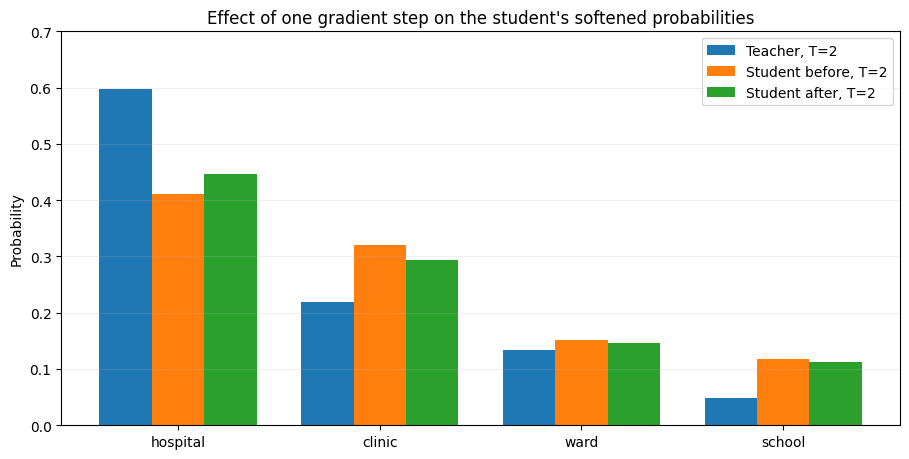

In [ ]:
positions = np.arange(len(vocab))
width = 0.26
fig, ax = plt.subplots(figsize=(9.2, 4.7))
ax.bar(positions-width, pt_2, width, label="Teacher, T=2")
ax.bar(positions, ps_2, width, label="Student before, T=2")
ax.bar(positions+width, new_q2, width, label="Student after, T=2")
ax.set_xticks(positions, vocab)
ax.set_ylabel("Probability")
ax.set_title("Effect of one gradient step on the student's softened probabilities")
ax.set_ylim(0, 0.70)
ax.legend()
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

## Final answers at a glance

| Part | Result |
|---|---|
| (a) Teacher, $T=1$ | $[0.839025,\ 0.113550,\ 0.041773,\ 0.005653]$ |
| (a) Student, $T=1$ | $[0.548260,\ 0.332537,\ 0.074199,\ 0.045004]$ |
| (b) Teacher, $T=2$ | $[0.597695,\ 0.219880,\ 0.133364,\ 0.049062]$ |
| (b) Student, $T=2$ | $[0.410984,\ 0.320075,\ 0.151193,\ 0.117749]$ |
| (c) KL divergence | $0.081607$ |
| (d) Cross-entropy | $0.601005$ |
| (e) Original loss | $0.463717$ |
| (f) Gradient | $[-0.412581,\ 0.266463,\ 0.054928,\ 0.091189]$ |
| (g) Updated logits | $[3.206290,\ 2.366768,\ 0.972536,\ 0.454405]$ |
| (g) Updated loss | $0.349256$ |

**Observation:** The first optimization step increases the logit for the correct word, *hospital*, while reducing the competing logits. The total loss falls from **0.463717** to **0.349256**, which is the expected direction of improvement.
